# EMQA_L2_coint_daily

**Romania and Hungary: coupled markets, a spread that keeps closing**

Energy Markets Quantitative Analysis (EMQA), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L2/EMQA_L2_coint_daily/EMQA_L2_coint_daily.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# course chart style: transparent background, no grid, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}   # fixed colour per entity


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, y),
                   frameon=False, handlelength=2.0, columnspacing=1.2)

## Data and cut-off

In [3]:
TZ = "Europe/Brussels"
PD = pd.read_csv(DATA + "power_da_prices_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
_hydro = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", usecols=["date_cet", "hydro_run_of_river"],
                     parse_dates=["date_cet"]).set_index("date_cet")["hydro_run_of_river"]
# cut-off = last complete month covered by the prices and the Romanian generation data
_raw_last = min(PD["RO"].dropna().index.max(), _hydro.dropna().index.max())
END = pd.Timestamp(((_raw_last + pd.Timedelta(days=1)).to_period("M").to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp("2022-01-01")
N_TEST, N_BURN = 365, 182                                  # test year; burn-in (its forecasts only feed QRA, CP, HS)
TEST0 = END - pd.Timedelta(days=N_TEST - 1)
FC0 = TEST0 - pd.Timedelta(days=N_BURN)
FDAYS = pd.date_range(FC0, END, freq="D")                  # burn-in + test days
TDAYS = pd.date_range(TEST0, END, freq="D")                # test days
print("cut-off:", END.date(), "| test year:", TEST0.date(), "to", END.date())

cut-off: 2026-10-31 | test year: 2025-11-01 to 2026-10-31


## Unit roots and cointegration, daily prices since 2022

In [4]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen


def adf_p(x):
    return adfuller(x, regression="c", autolag="AIC")[1]


DLY = PD.loc[START:END, ["RO", "HU", "DE_LU"]].dropna()
co = {}
for z in ["RO", "HU", "DE_LU"]:
    co[f"adf_{z}"] = adf_p(DLY[z])
for z in ["HU", "DE_LU"]:
    eg = coint(DLY["RO"], DLY[z], trend="c", autolag="aic")
    ols = sm.OLS(DLY["RO"], sm.add_constant(DLY[z])).fit()
    u = ols.resid
    phi = sm.OLS(u.values[1:], u.values[:-1]).fit().params[0]   # AR(1) of the spread residual
    jo = coint_johansen(DLY[["RO", z]].values, det_order=0, k_ar_diff=6)
    co[z] = {"eg": eg[0], "eg_cv5": eg[2][1], "beta": ols.params[z], "hl": np.log(0.5) / np.log(phi),
             "tr0": jo.lr1[0], "tr0_cv": jo.cvt[0, 1], "tr1": jo.lr1[1], "tr1_cv": jo.cvt[1, 1],
             "sd_spread": (DLY["RO"] - DLY[z]).std(), "mean_spread": (DLY["RO"] - DLY[z]).mean()}
print(pd.DataFrame({z: co[z] for z in ["HU", "DE_LU"]}).round(3).to_string())

                  HU    DE_LU
eg           -10.583   -5.794
eg_cv5        -3.340   -3.340
beta           0.963    0.947
hl             0.769    1.515
tr0          139.689  128.204
tr0_cv        15.494   15.494
tr1            6.210    6.580
tr1_cv         3.842    3.842
sd_spread     15.079   37.789
mean_spread   -2.074   21.059


## Hours with identical prices in the test year (coupled, uncongested border)

In [5]:
HP = pd.read_csv(DATA + "power_da_prices_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "RO", "HU"])
HP.index = pd.to_datetime(HP.index, utc=True).tz_convert(TZ)
hpt = HP.loc[str(TEST0.date()):str(END.date())]
EQ_HU = (np.abs(hpt["RO"] - hpt["HU"]) < 0.01).mean() * 100

## The chart

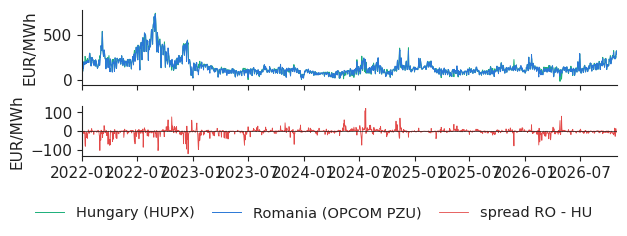

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(6.4, 2.4), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
axs[0].plot(DLY.index, DLY["HU"], color=PAL["HU"], lw=0.7, label="Hungary (HUPX)")
axs[0].plot(DLY.index, DLY["RO"], color=PAL["RO"], lw=0.7, label="Romania (OPCOM PZU)")
axs[0].set_ylabel("EUR/MWh")
axs[1].plot(DLY.index, DLY["RO"] - DLY["HU"], color=PAL["c8"], lw=0.6, label="spread RO - HU")
axs[1].axhline(0, color="#222222", lw=0.5)
axs[1].set_ylabel("EUR/MWh")
axs[1].set_xlim(DLY.index[0], DLY.index[-1])
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.15, 1, 1))
plt.savefig('coint_daily.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()

In [7]:
print("Numbers on the slide")
print(f'  first day: {str(DLY.index.min().date()):s}')
print(f'  mean spread RO - HU: {co["HU"]["mean_spread"]:.2f}')
print(f'  standard deviation of the spread RO - HU: {co["HU"]["sd_spread"]:.2f}')
print(f'  mean spread RO - DE-LU: {co["DE_LU"]["mean_spread"]:.2f}')
print(f'  standard deviation of the spread RO - DE-LU: {co["DE_LU"]["sd_spread"]:.2f}')
print(f'  hours RO = HU in the test year, %: {EQ_HU:.1f}')
print(f'  beta RO on HU: {co["HU"]["beta"]:.3f}')
print(f'  Engle-Granger statistic: {co["HU"]["eg"]:.2f}')
print(f'  Engle-Granger 5% critical value: {co["HU"]["eg_cv5"]:.2f}')
print(f'  half-life of a spread shock, days: {co["HU"]["hl"]:.1f}')
print(f'  Johansen trace r = 0: {co["HU"]["tr0"]:.2f}')
print(f'  Johansen trace r <= 1: {co["HU"]["tr1"]:.2f}')
print(f'  ADF p-value, Romanian price level: {co["adf_RO"]:.4f}')

Numbers on the slide
  first day: 2022-01-01
  mean spread RO - HU: -2.07
  standard deviation of the spread RO - HU: 15.08
  mean spread RO - DE-LU: 21.06
  standard deviation of the spread RO - DE-LU: 37.79
  hours RO = HU in the test year, %: 10.1
  beta RO on HU: 0.963
  Engle-Granger statistic: -10.58
  Engle-Granger 5% critical value: -3.34
  half-life of a spread shock, days: 0.8
  Johansen trace r = 0: 139.69
  Johansen trace r <= 1: 6.21
  ADF p-value, Romanian price level: 0.0636
